# TABR datatest event-level report — final model

Notebook laporan event-level final.

Konfigurasi final:
- Model: `convat_apex_anxiety_qwalk_q12_q3_q4`
- Aggregation: `mean`
- Threshold: `0.235`

Output:
- Tabel data test event: `No`, `Kode Video`, `Kondisi`, `Label`, `Durasi`, `Jumlah Frame`
- Tabel hasil prediksi event: `No`, `Kode Video`, `Label Aktual`, `Label Prediksi`, `Status`
- Confusion matrix
- Metrik evaluasi: accuracy, recall, precision, f1-score


In [1]:
from __future__ import annotations

import gc
import json
import os
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from IPython.display import Markdown, display
from scipy.special import expit
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support

sns.set_theme(style='whitegrid')
ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

TABR_ROOT = ROOT / 'third_party' / 'tabular-dl-tabr-official'
os.environ['PROJECT_DIR'] = str(TABR_ROOT)
if str(TABR_ROOT) not in sys.path:
    sys.path.append(str(TABR_ROOT))

import lib
from bin.tabr import Model

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
EXP_ROOT = TABR_ROOT / 'exp' / 'tabr'
DATA_ROOT = TABR_ROOT / 'data'
MODEL_SPECS = [
    {
        'label': 'qwalk_q12_q3_q4_final',
        'exp_name': 'convat_apex_anxiety_qwalk_q12_q3_q4',
        'mode': 'qwalkforward',
        'aggregation': 'p90',
        'threshold': 0.500,
    },
]
FINAL_SPEC = MODEL_SPECS[0]
FINAL_AGGREGATION = FINAL_SPEC['aggregation']
FINAL_THRESHOLD = float(FINAL_SPEC['threshold'])
TOP_K = 3
FPS = 25
EVAL_ROOT = ROOT / 'output/apex/datatest/event_level_final_report'
CM_ROOT = EVAL_ROOT / 'confusion_matrices'
EVAL_ROOT.mkdir(parents=True, exist_ok=True)
CM_ROOT.mkdir(parents=True, exist_ok=True)
display(pd.DataFrame(MODEL_SPECS))
print(f'Root: {ROOT}')
print(f'Device: {device}')


,label,exp_name,mode,aggregation,threshold
0,qwalk_q12_q3_q4_final,convat_apex_anxiety_qwalk_q12_q3_q4,qwalkforward,p90,0.5


Root: /home/ryuko/skripsi/Skripsi/Convat-1st
Device: cuda


In [2]:
FEATURE_PATHS = [
    ROOT / 'output/apex/datatest/features/15_04_2026/poc_abs_test.xlsx',
    ROOT / 'output/apex/datatest/features/17_04_2026/poc_abs_test.xlsx',
]

SELECTED_HIGH = [
    'naufal_abid_aurizky',
    'hafif_nurrahmad',
    'bisma_adhiaksa',
    'tsabita_keizya_vanya_putri',
    'raihan_daffa_izzuddin',
    'andy',
    'dicky_darmawan',
    'fata_haidar_aly',
    'muhammad_ihsan_rahmatullah',
    'raymon_devtant',
]

SELECTED_LOW = [
    'muhammad_daniel_assaqovi',
    'sileysa_faedatul_nuraini',
    'ilham_dharma_atmaja',
    'abelas_solihin',
    'dewi_anggraini_meita_sari',
    'farrel_andika_chandra',
    'muhammad_nuril_huda',
    'muhammad_rizky_firdiansyah',
    'rachmad_aprisandhy',
    'zukhrufian_abdullah',
]

SELECTED_SUBJECTS = SELECTED_HIGH + SELECTED_LOW
EXPECTED_LABEL_BY_BASE = {
    **{name: 'anxiety_tinggi' for name in SELECTED_HIGH},
    **{name: 'anxiety_rendah' for name in SELECTED_LOW},
}

def label_to_int(label: str) -> int:
    return 1 if str(label) in {'anxiety_tinggi', 'anxiety', '1', 'tinggi'} else 0


def int_to_label(value: int) -> str:
    return 'anxiety_tinggi' if int(value) == 1 else 'anxiety_rendah'


def participant_base(value: str) -> str:
    return re.sub(r'_\d+$', '', str(value))


def filter_selected_subjects(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out['participant_base'] = out['participant_raw'].map(participant_base)
    out = out[out['participant_base'].isin(SELECTED_SUBJECTS)].copy()
    out = out[out['label'] == out['participant_base'].map(EXPECTED_LABEL_BY_BASE)].copy()
    return out


def load_datatest_features(paths: list[Path]) -> pd.DataFrame:
    dfs = []
    for path in paths:
        if not path.exists():
            raise FileNotFoundError(f'Feature file not found: {path}')
        df = pd.read_excel(path)
        if 'date' not in df.columns:
            df['date'] = path.parent.name
        dfs.append(df)
    out = pd.concat(dfs, ignore_index=True)
    out = filter_selected_subjects(out)
    out['true_label'] = out['label'].map(label_to_int).astype(int)
    out['event_key'] = (
        out['date'].astype(str) + '|' + out['participant_raw'].astype(str) + '|' + out['question'].astype(str) + '|' +
        out['sample'].astype(str) + '|' + out['event_clip'].astype(str) + '|' + out['event_no'].astype(str)
    )
    out['kode_event'] = out['sample'].astype(str) + ' / ' + out['event_clip'].astype(str)
    return out


frame_df = load_datatest_features(FEATURE_PATHS)
missing = sorted(set(SELECTED_SUBJECTS) - set(frame_df['participant_base'].unique()))
if missing:
    raise ValueError(f'Missing selected subjects: {missing}')

subject_label_counts = (
    frame_df.drop_duplicates('participant_base')['label']
    .value_counts()
    .reindex(['anxiety_tinggi', 'anxiety_rendah'], fill_value=0)
)
if subject_label_counts.to_dict() != {'anxiety_tinggi': 10, 'anxiety_rendah': 10}:
    raise ValueError(f'Expected 10 tinggi + 10 rendah, got: {subject_label_counts.to_dict()}')
print('Jumlah subjek:', subject_label_counts.to_dict())

datatest_table = (
    frame_df
    .groupby('event_key', sort=False)
    .agg(
        kode_video=('kode_event', 'first'),
        kondisi=('condition', 'first'),
        label=('label', 'first'),
        jumlah_frame=('frame', 'count'),
    )
    .reset_index(drop=True)
)
datatest_table.insert(0, 'No', np.arange(1, len(datatest_table) + 1))
datatest_table['durasi'] = datatest_table['jumlah_frame'] / FPS
datatest_table = datatest_table[['No', 'kode_video', 'kondisi', 'label', 'durasi', 'jumlah_frame']]
datatest_table = datatest_table.rename(columns={
    'kode_video': 'Kode Video',
    'kondisi': 'Kondisi',
    'label': 'Label',
    'durasi': 'Durasi',
    'jumlah_frame': 'Jumlah Frame',
})
display(Markdown('## Tabel data test event-level'))
display(datatest_table)


Jumlah subjek: {'anxiety_tinggi': 10, 'anxiety_rendah': 10}


## Tabel data test event-level

,No,Kode Video,Kondisi,Label,Durasi,Jumlah Frame
0,1,Abelas Solihin_1_15d591ce-051a-47f2-ac38-367c1...,anxiety_rendah,anxiety_rendah,0.28,7
1,2,Abelas Solihin_1_15d591ce-051a-47f2-ac38-367c1...,anxiety_rendah,anxiety_rendah,0.64,16
2,3,Abelas Solihin_1_15d591ce-051a-47f2-ac38-367c1...,anxiety_rendah,anxiety_rendah,0.96,24
3,4,Abelas Solihin_1_15d591ce-051a-47f2-ac38-367c1...,anxiety_rendah,anxiety_rendah,1.24,31
4,5,Abelas Solihin_1_15d591ce-051a-47f2-ac38-367c1...,anxiety_rendah,anxiety_rendah,1.72,43
...,...,...,...,...,...,...
687,688,Raihan Daffa Izzuddin_5_e1e6b3e5-a2d1-4832-a1f...,anxiety_tinggi,anxiety_tinggi,0.40,10
688,689,Raihan Daffa Izzuddin_5_e1e6b3e5-a2d1-4832-a1f...,anxiety_tinggi,anxiety_tinggi,0.16,4
689,690,Raihan Daffa Izzuddin_5_e1e6b3e5-a2d1-4832-a1f...,anxiety_tinggi,anxiety_tinggi,0.32,8
690,691,Raihan Daffa Izzuddin_5_e1e6b3e5-a2d1-4832-a1f...,anxiety_tinggi,anxiety_tinggi,0.20,5


In [3]:
def load_best_seed_report(exp_name: str) -> tuple[int, dict, Path]:
    eval_dir = EXP_ROOT / exp_name / '0-evaluation'
    rows = []
    for run_dir in sorted([x for x in eval_dir.iterdir() if x.is_dir() and x.name.isdigit()]):
        report_path = run_dir / 'report.json'
        if not report_path.exists():
            continue
        report = json.loads(report_path.read_text())
        rows.append((int(run_dir.name), report, run_dir))
    if not rows:
        raise FileNotFoundError(f'No report.json found for {exp_name}')
    return max(rows, key=lambda x: x[1]['metrics']['val']['score'])


def load_run_config(exp_name: str, best_seed: int, report: dict) -> dict:
    seed_toml = EXP_ROOT / exp_name / f'{best_seed}.toml'
    if seed_toml.exists():
        return lib.load_config(seed_toml)
    if 'config' in report:
        return report['config']
    tuning_toml = EXP_ROOT / exp_name / '0-tuning.toml'
    if tuning_toml.exists():
        return lib.load_config(tuning_toml)
    raise FileNotFoundError(f'No config found for {exp_name} seed {best_seed}')


def resolve_data_dir(data_path: str) -> Path:
    if data_path.startswith(':data/'):
        return DATA_ROOT / data_path.removeprefix(':data/')
    return Path(data_path)


def load_model_bundle(exp_name: str) -> dict:
    best_seed, report, best_run_dir = load_best_seed_report(exp_name)
    cfg = load_run_config(exp_name, best_seed, report)
    data_dir = resolve_data_dir(cfg['data']['path'])
    feature_cols = json.loads((data_dir / 'feature_cols.json').read_text())
    dataset = lib.build_dataset(**cfg['data']).to_torch(device)
    model = Model(
        n_num_features=dataset.n_num_features,
        n_bin_features=dataset.n_bin_features,
        cat_cardinalities=dataset.cat_cardinalities(),
        n_classes=dataset.n_classes(),
        **cfg['model'],
    ).to(device)
    checkpoint = lib.load_checkpoint(best_run_dir)
    model.load_state_dict(checkpoint['model'])
    model.eval()
    candidate_x = {key[2:]: dataset.data[key]['train'] for key in dataset.data if key.startswith('X_')}
    candidate_y = dataset.Y['train']
    return {
        'model': model,
        'dataset': dataset,
        'candidate_x': candidate_x,
        'candidate_y': candidate_y,
        'feature_cols': feature_cols,
        'context_size': cfg['context_size'],
        'best_seed': best_seed,
        'data_path': cfg['data']['path'],
    }


def release_model_bundle(bundle: dict) -> None:
    del bundle
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


In [4]:
@torch.inference_mode()
def predict_frame_probs(bundle: dict, df: pd.DataFrame, batch_size: int = 512, progress_every: int = 500) -> np.ndarray:
    feature_cols = bundle['feature_cols']
    missing = [c for c in feature_cols if c not in df.columns]
    if missing:
        raise KeyError(f'Missing feature cols: {missing[:20]}')
    x_np = df[feature_cols].to_numpy(dtype=np.float32)
    probs = []
    total = len(x_np)
    for start in range(0, total, batch_size):
        if progress_every and start % progress_every < batch_size:
            print(f'  frame {start}/{total}')
        xb = torch.as_tensor(x_np[start:start + batch_size], device=device)
        for i in range(xb.shape[0]):
            x = {'num': xb[i:i+1]}
            logit = bundle['model'](
                x_=x,
                y=None,
                candidate_x_=bundle['candidate_x'],
                candidate_y=bundle['candidate_y'],
                context_size=bundle['context_size'],
                is_train=False,
            ).squeeze(-1).item()
            probs.append(float(expit(logit)))
    return np.asarray(probs, dtype=float)


def aggregate_probs(values, method: str, top_k: int = TOP_K) -> float:
    arr = np.asarray(list(values), dtype=float)
    if len(arr) == 0:
        return np.nan
    if method == 'mean':
        return float(np.mean(arr))
    if method == 'max':
        return float(np.max(arr))
    if method == 'p90':
        return float(np.quantile(arr, 0.90))
    if method == 'top3_mean':
        k = min(top_k, len(arr))
        return float(np.mean(np.sort(arr)[-k:]))
    raise ValueError(f'Unknown aggregation method: {method}')


In [5]:
def make_event_predictions(frame_df: pd.DataFrame, spec: dict) -> pd.DataFrame:
    rows = []
    meta_cols = ['event_key', 'kode_event', 'condition', 'label', 'true_label', 'participant_base', 'participant_raw', 'question', 'sample', 'event_clip', 'event_no']
    method = spec['aggregation']
    threshold = float(spec['threshold'])
    for event_key, g in frame_df.groupby('event_key', sort=False):
        first = g.iloc[0]
        prob = aggregate_probs(g['prob_anxiety_tinggi'], method)
        row = {col: first[col] for col in meta_cols if col in g.columns}
        row.update({
            'model_label': spec['label'],
            'exp_name': spec['exp_name'],
            'aggregation': method,
            'threshold': threshold,
            'agg_prob_anxiety_tinggi': prob,
            'pred_label': int(prob >= threshold),
            'n_frames': len(g),
        })
        rows.append(row)
    return pd.DataFrame(rows)


def metrics_table(df: pd.DataFrame) -> pd.DataFrame:
    y_true = df['true_label'].astype(int).to_numpy()
    y_pred = df['pred_label'].astype(int).to_numpy()
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    recall_rendah = tn / (tn + fp)
    recall_tinggi = tp / (tp + fn)
    return pd.DataFrame([{
        'model': FINAL_SPEC['label'],
        'exp_name': FINAL_SPEC['exp_name'],
        'aggregation': FINAL_AGGREGATION,
        'threshold': FINAL_THRESHOLD,
        'n': len(df),
        'tn': int(tn),
        'fp': int(fp),
        'fn': int(fn),
        'tp': int(tp),
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision,
        'recall': recall,
        'f1-score': f1,
        'recall_rendah': recall_rendah,
        'recall_tinggi': recall_tinggi,
        'recall_gap': abs(recall_rendah - recall_tinggi),
    }])


def make_prediction_table(prediction_df: pd.DataFrame) -> pd.DataFrame:
    table = prediction_df[['kode_event', 'true_label', 'pred_label']].copy()
    table.insert(0, 'No', np.arange(1, len(table) + 1))
    table['Label Aktual'] = table['true_label'].map(int_to_label)
    table['Label Prediksi'] = table['pred_label'].map(int_to_label)
    table['Status'] = np.where(table['true_label'] == table['pred_label'], 'Benar', 'Salah')
    table = table.rename(columns={'kode_event': 'Kode Video'})
    return table[['No', 'Kode Video', 'Label Aktual', 'Label Prediksi', 'Status']]


def plot_confusion(df: pd.DataFrame) -> Path:
    y_true = df['true_label'].astype(int).to_numpy()
    y_pred = df['pred_label'].astype(int).to_numpy()
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    path = CM_ROOT / 'confusion_matrix__final_qwalk_q12_q3_q4__mean__thr_0.235.png'
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', cbar=False,
        xticklabels=['rendah', 'tinggi'], yticklabels=['rendah', 'tinggi'], ax=ax,
    )
    ax.set_xlabel('Label Prediksi')
    ax.set_ylabel('Label Aktual')
    ax.set_title('Confusion Matrix')
    plt.tight_layout()
    fig.savefig(path, dpi=160)
    plt.show()
    plt.close(fig)
    return path


# Model final: `qwalk_q12_q3_q4_final`

`convat_apex_anxiety_qwalk_q12_q3_q4` | aggregation=`p90` | threshold=`0.5`

2026-05-23 01:46:31.612 | INFO     | lib.data:build_dataset:338 - Using cached dataset: build_dataset__convat_apex_anxiety_qwalk_q12_q3_q4__None__None__None__None__72__d10c1508d8934c1de65e6394f780722e.pickle


best_seed= 4 features= 392 data_path= :data/convat_apex_anxiety_qwalk_q12_q3_q4
  frame 0/8223
  frame 512/8223
  frame 1024/8223
  frame 1536/8223
  frame 2048/8223
  frame 2560/8223
  frame 3072/8223
  frame 3584/8223
  frame 4096/8223
  frame 4608/8223
  frame 5120/8223
  frame 5632/8223
  frame 6144/8223
  frame 6656/8223
  frame 7168/8223
  frame 7680/8223
  frame 8192/8223


## Tabel hasil prediksi event-level

,No,Kode Video,Label Aktual,Label Prediksi,Status
0,1,Abelas Solihin_1_15d591ce-051a-47f2-ac38-367c1...,anxiety_rendah,anxiety_rendah,Benar
1,2,Abelas Solihin_1_15d591ce-051a-47f2-ac38-367c1...,anxiety_rendah,anxiety_tinggi,Salah
2,3,Abelas Solihin_1_15d591ce-051a-47f2-ac38-367c1...,anxiety_rendah,anxiety_rendah,Benar
3,4,Abelas Solihin_1_15d591ce-051a-47f2-ac38-367c1...,anxiety_rendah,anxiety_rendah,Benar
4,5,Abelas Solihin_1_15d591ce-051a-47f2-ac38-367c1...,anxiety_rendah,anxiety_tinggi,Salah
...,...,...,...,...,...
687,688,Raihan Daffa Izzuddin_5_e1e6b3e5-a2d1-4832-a1f...,anxiety_tinggi,anxiety_rendah,Salah
688,689,Raihan Daffa Izzuddin_5_e1e6b3e5-a2d1-4832-a1f...,anxiety_tinggi,anxiety_rendah,Salah
689,690,Raihan Daffa Izzuddin_5_e1e6b3e5-a2d1-4832-a1f...,anxiety_tinggi,anxiety_tinggi,Benar
690,691,Raihan Daffa Izzuddin_5_e1e6b3e5-a2d1-4832-a1f...,anxiety_tinggi,anxiety_tinggi,Benar


## Gambar confusion matrix

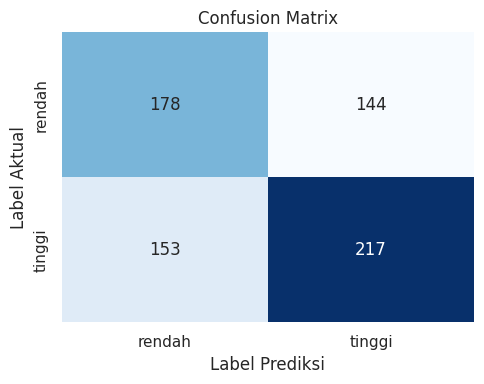

Saved confusion matrix: /home/ryuko/skripsi/Skripsi/Convat-1st/output/apex/datatest/event_level_final_report/confusion_matrices/confusion_matrix__final_qwalk_q12_q3_q4__mean__thr_0.235.png


## Metrik evaluasi

,model,exp_name,aggregation,threshold,n,tn,fp,fn,tp,accuracy,precision,recall,f1-score,recall_rendah,recall_tinggi,recall_gap
0,qwalk_q12_q3_q4_final,convat_apex_anxiety_qwalk_q12_q3_q4,p90,0.5,692,178,144,153,217,0.570809,0.569436,0.569641,0.569442,0.552795,0.586486,0.033691


## Classification report

                precision    recall  f1-score   support

anxiety_rendah       0.54      0.55      0.55       322
anxiety_tinggi       0.60      0.59      0.59       370

      accuracy                           0.57       692
     macro avg       0.57      0.57      0.57       692
  weighted avg       0.57      0.57      0.57       692



In [6]:
display(Markdown(f"# Model final: `{FINAL_SPEC['label']}`"))
display(Markdown(f"`{FINAL_SPEC['exp_name']}` | aggregation=`{FINAL_AGGREGATION}` | threshold=`{FINAL_THRESHOLD}`"))

bundle = load_model_bundle(FINAL_SPEC['exp_name'])
print('best_seed=', bundle['best_seed'], 'features=', len(bundle['feature_cols']), 'data_path=', bundle['data_path'])
try:
    work = frame_df.copy()
    work['prob_anxiety_tinggi'] = predict_frame_probs(bundle, work)
finally:
    release_model_bundle(bundle)

prediction_df = make_event_predictions(work, FINAL_SPEC)
prediction_table = make_prediction_table(prediction_df)
eval_metrics_table = metrics_table(prediction_df)

display(Markdown('## Tabel hasil prediksi event-level'))
display(prediction_table)

display(Markdown('## Gambar confusion matrix'))
cm_path = plot_confusion(prediction_df)
print(f'Saved confusion matrix: {cm_path}')

display(Markdown('## Metrik evaluasi'))
display(eval_metrics_table)

display(Markdown('## Classification report'))
print(classification_report(
    prediction_df['true_label'].astype(int),
    prediction_df['pred_label'].astype(int),
    labels=[0, 1],
    target_names=['anxiety_rendah', 'anxiety_tinggi'],
    zero_division=0,
))


In [7]:
with pd.ExcelWriter(EVAL_ROOT / 'event_level_final_report.xlsx') as writer:
    datatest_table.to_excel(writer, sheet_name='tabel_datatest_event', index=False)
    prediction_table.to_excel(writer, sheet_name='tabel_prediksi_event', index=False)
    eval_metrics_table.to_excel(writer, sheet_name='metrik_evaluasi', index=False)
    prediction_df.to_excel(writer, sheet_name='raw_event_predictions', index=False)

print(f'Saved: {EVAL_ROOT / "event_level_final_report.xlsx"}')


Saved: /home/ryuko/skripsi/Skripsi/Convat-1st/output/apex/datatest/event_level_final_report/event_level_final_report.xlsx
